- **Гипотеза 1.** Насколько уменьшится аренда (длительность аренды) велосипедов от зимних условий, (это гололед, снег, температура), стоит ли заменить летние велосипеды на более снаряженные

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq

- читаю файл "../../../data_after_preprocessing/drd_with_weather.parquet"

In [2]:
drd_with_weather = pd.read_parquet('../../../data_after_preprocessing/drd_with_weather.parquet')
drd_with_weather

,rideable_type,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
0,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301
1,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334
2,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,18.000000,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333
3,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000
4,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,31.900000,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800
16086668,electric_bike,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934
16086669,electric_bike,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117
16086670,electric_bike,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934


- смотрю какие есть погодные условия

In [3]:
drd_with_weather['icon'].unique()

<ArrowStringArray>
['rain', 'partly-cloudy-day', 'cloudy', 'clear-day', 'wind', 'snow']
Length: 6, dtype: str

- делаю выборку по погодным условиям (снег и температура < 0) 

In [4]:
weather_snow = drd_with_weather[(drd_with_weather['icon'] == 'snow') | (drd_with_weather['feelslike'] < 0)]
weather_snow

,rideable_type,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes
1498218,classic_bike,2020-12-27 12:30:28,2020-12-27 12:36:12,member,2020-12-27,1.0,-1.4,60.599998,-5.9,16.0,17.200001,0.00,0.0,partly-cloudy-day,5.733333
1498227,docked_bike,2020-12-07 19:17:43,2020-12-07 19:27:19,member,2020-12-07,2.3,-1.0,57.799999,-5.3,16.0,22.100000,0.00,0.0,partly-cloudy-day,9.600000
1498231,docked_bike,2020-12-07 14:34:29,2020-12-07 20:34:54,casual,2020-12-07,2.3,-1.0,57.799999,-5.3,16.0,22.100000,0.00,0.0,partly-cloudy-day,360.416656
1498232,docked_bike,2020-12-07 14:31:24,2020-12-07 14:40:12,casual,2020-12-07,2.3,-1.0,57.799999,-5.3,16.0,22.100000,0.00,0.0,partly-cloudy-day,8.800000
1498238,classic_bike,2020-12-25 11:51:26,2020-12-25 11:56:46,member,2020-12-25,2.1,-2.5,64.599998,-4.2,15.5,28.900000,29.17,0.0,rain,5.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12855507,electric_bike,2024-02-17 20:25:06,2024-02-17 20:33:56,casual,2024-02-17,2.4,-2.0,57.500000,-6.0,15.0,35.599998,20.83,5.6,snow,8.833333
12855510,classic_bike,2024-02-17 16:53:30,2024-02-17 17:29:49,member,2024-02-17,2.4,-2.0,57.500000,-6.0,15.0,35.599998,20.83,5.6,snow,36.316666
12855516,classic_bike,2024-02-17 16:55:35,2024-02-17 17:05:24,casual,2024-02-17,2.4,-2.0,57.500000,-6.0,15.0,35.599998,20.83,5.6,snow,9.816667
12855518,classic_bike,2024-02-17 11:40:55,2024-02-17 11:54:50,member,2024-02-17,2.4,-2.0,57.500000,-6.0,15.0,35.599998,20.83,5.6,snow,13.916667


- вывожу среднее время аренды

In [5]:
weather_snow['duration_in_minutes'].mean()

np.float32(16.949125)

- вывожу медианное время аренды

In [6]:
weather_snow['duration_in_minutes'].median()

np.float32(9.416667)

- считаю сумму аренды велосипедов (в минутах)

In [7]:
int(weather_snow['duration_in_minutes'].sum())

7671937

- считаю в процентах от всего количества (столько занимают зимние погодные условия в днях)

In [8]:
round((weather_snow['date'].nunique() / drd_with_weather['date'].nunique()) * 100, 2)

7.39

- считаю в процентах от всего количества (столько занимают зимние погодные условия в количестве аренд)

In [9]:
round((452645 / 16078055) * 100, 2)

2.82

- выведу сразу два гарфика
    - Первый - Средняя длительность аренды при разных тивах погоды
    - Второй - Количество аренд при разных типах погоды

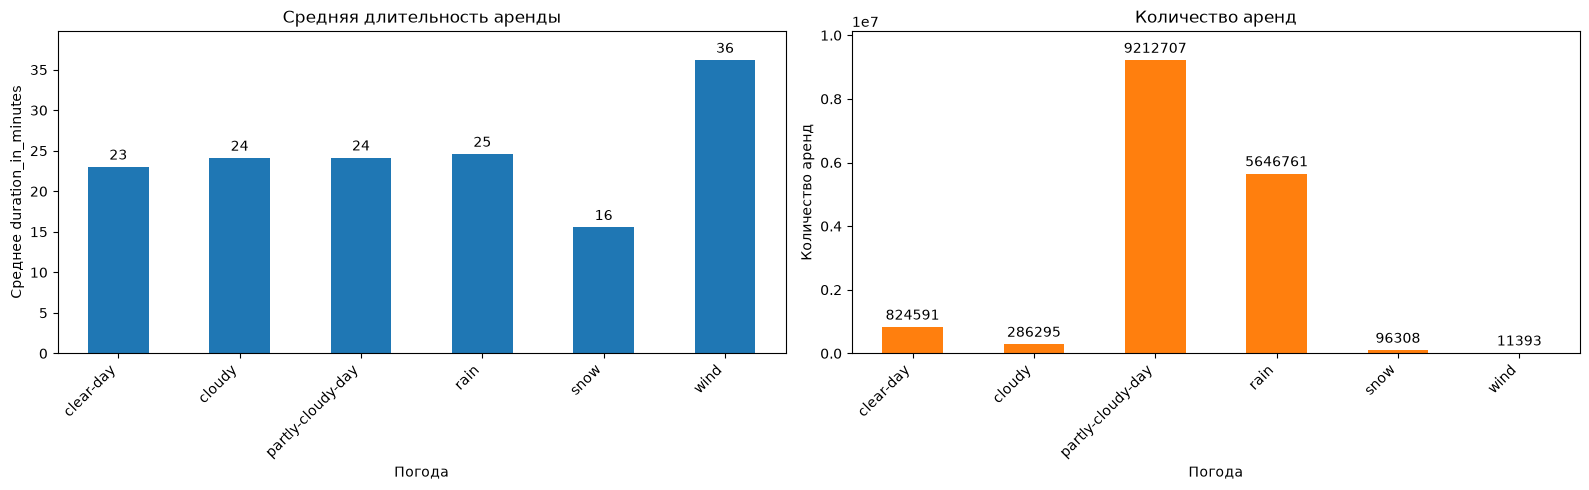

In [10]:
grouped = drd_with_weather.groupby('icon')['duration_in_minutes']
mean_duration = grouped.mean()
rent_count = grouped.size()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# График 1: средняя длительность
mean_duration.plot(kind='bar', ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt='%.0f', padding=3)
axes[0].margins(y=0.1)
axes[0].set_title('Средняя длительность аренды')
axes[0].set_xlabel('Погода')
axes[0].set_ylabel('Среднее duration_in_minutes')
axes[0].tick_params(axis='x', rotation=45)
plt.setp(axes[0].get_xticklabels(), ha='right')

# График 2: количество аренд
rent_count.plot(kind='bar', ax=axes[1], color='tab:orange')
axes[1].bar_label(axes[1].containers[0], fmt='%.0f', padding=3)
axes[1].margins(y=0.1)
axes[1].set_title('Количество аренд')
axes[1].set_xlabel('Погода')
axes[1].set_ylabel('Количество аренд')
axes[1].tick_params(axis='x', rotation=45)
plt.setp(axes[1].get_xticklabels(), ha='right')

plt.tight_layout()
plt.show()

### Промежуточный вывод - разница между зимними условиями и частичной облачностью (погода при которой чаще всего берут в аренду)
    - состовляет 8 минут 
    - при этом разница почти в 100 раз по количеству велосипедов взятых в аренду

- Хочу добавить сезоны и посмотреть в разрезе сезонов

In [11]:
seasons = {
    12: 'зима', 1: 'зима', 2: 'зима',
    3: 'весна', 4: 'весна', 5: 'весна',
    6: 'лето', 7: 'лето', 8: 'лето',
    9: 'осень', 10: 'осень', 11: 'осень',
}

In [12]:
drd_with_weather['season'] = drd_with_weather['date'].dt.month.map(seasons)

In [13]:
drd_with_weather

,rideable_type,started_at,ended_at,member_casual,date,temp,feelslike,humidity,dew,visibility,windspeed,precipcover,snow,icon,duration_in_minutes,season
0,docked_bike,2020-05-30 17:25:29.000,2020-05-31 18:25:22.000,casual,2020-05-30,24.299999,24.100000,55.700001,13.800000,16.0,32.700001,4.17,0.0,rain,1499.883301,весна
1,docked_bike,2020-05-09 14:42:04.000,2020-05-09 15:06:33.000,member,2020-05-09,6.800000,3.600000,41.900002,-5.700000,16.0,40.799999,0.00,0.0,partly-cloudy-day,24.483334,весна
2,docked_bike,2020-05-24 17:27:19.000,2020-05-24 17:43:51.000,member,2020-05-24,18.000000,18.000000,82.300003,14.900000,15.8,20.900000,0.00,0.0,cloudy,16.533333,весна
3,docked_bike,2020-05-27 15:29:52.000,2020-05-27 15:47:13.000,casual,2020-05-27,22.200001,22.200001,79.199997,18.200001,15.8,17.500000,0.00,0.0,partly-cloudy-day,17.350000,весна
4,docked_bike,2020-05-31 14:06:03.000,2020-05-31 14:30:30.000,casual,2020-05-31,20.400000,20.400000,39.500000,6.000000,16.0,28.500000,0.00,0.0,partly-cloudy-day,24.450001,весна
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16086667,electric_bike,2024-08-01 08:10:22.293,2024-08-01 08:10:37.641,member,2024-08-01,29.600000,31.900000,64.500000,21.600000,15.9,17.100000,0.00,0.0,partly-cloudy-day,0.255800,лето
16086668,electric_bike,2024-08-08 10:05:21.938,2024-08-08 10:21:46.654,member,2024-08-08,25.900000,26.200001,86.000000,23.400000,13.6,20.000000,50.00,0.0,rain,16.411934,лето
16086669,electric_bike,2024-08-03 16:29:32.252,2024-08-03 16:35:43.179,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,6.182117,лето
16086670,electric_bike,2024-08-03 02:49:45.661,2024-08-03 02:59:56.877,member,2024-08-03,27.900000,30.000000,71.099998,21.900000,15.7,34.599998,12.50,0.0,rain,10.186934,лето


In [15]:
daily = (drd_with_weather
         .groupby([drd_with_weather['date'].dt.date, 'season'], observed=True)
         .agg(rents=('duration_in_minutes', 'size'),
              mean_dur=('duration_in_minutes', 'mean'))
         .reset_index())

seasons_group = daily.groupby('season', observed=True)[['rents', 'mean_dur']].mean()
seasons_group

,rents,mean_dur
season,,
весна,10631.679198,26.969816
зима,5980.246537,18.126854
лето,12754.558696,29.894310
осень,10467.167582,24.194838


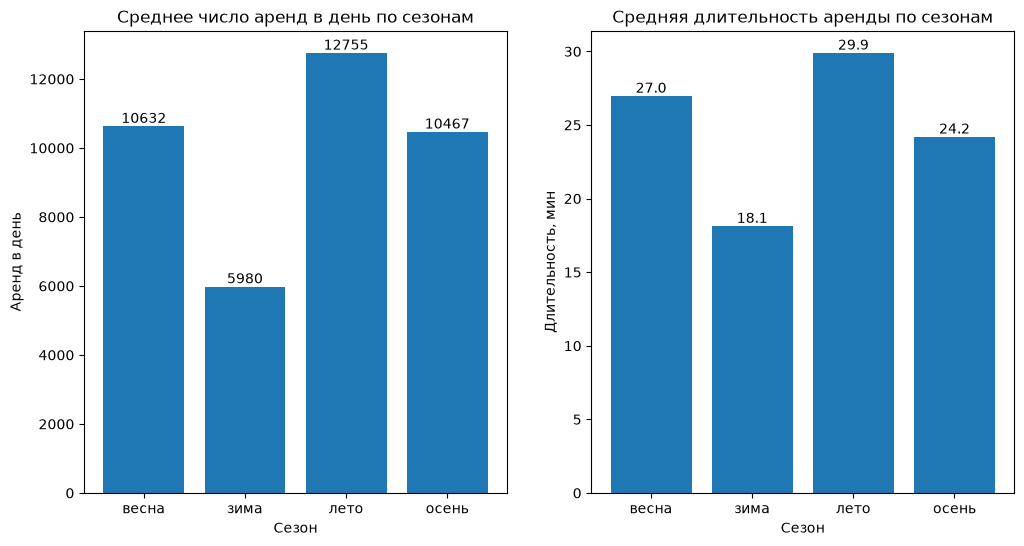

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

bars0 = axes[0].bar(
    seasons_group.index,
    seasons_group['rents']
)
axes[0].bar_label(bars0, fmt='%.0f')
axes[0].set_title('Среднее число аренд в день по сезонам')
axes[0].set_xlabel('Сезон')
axes[0].set_ylabel('Аренд в день')


bars1 = axes[1].bar(
    seasons_group.index,
    seasons_group['mean_dur']
)
axes[1].bar_label(bars1, fmt='%.1f')
axes[1].set_title('Средняя длительность аренды по сезонам')
axes[1].set_xlabel('Сезон')
axes[1].set_ylabel('Длительность, мин')

plt.show()

### Пока еще нельзя точно сказать на сколько зимние сильно влияют на аренду велосипедов, нужно посмотеть динамику за каждый год по сезонам,так можно будет отследить динамику

- добавляю столбец год

In [19]:
drd_with_weather['year'] = drd_with_weather['date'].dt.year

In [26]:
year_seasons = drd_with_weather.groupby(['year', 'season'])['duration_in_minutes'].sum().to_frame()
year_seasons

duration_in_minutes
year season                     
2020 весна           11920553.00
     зима             2271916.75
     лето            41073328.00
     осень           23810238.00
2021 весна           18045768.00
     зима             7424127.50
     лето            22663222.00
     осень           20746708.00
2022 весна           22564212.00
     зима             7741585.50
     лето            30367008.00
     осень           21940532.00
2023 весна           26548316.00
     зима            12307367.00
     лето            30909576.00
     осень           23739542.00
2024 весна           25219242.00
     зима             8186496.50
     лето            31197284.00

In [31]:
pivot = year_seasons['duration_in_minutes'].unstack('season')
pivot = pivot[['зима', 'весна', 'лето', 'осень']]  

In [32]:
pivot

season,зима,весна,лето,осень
year,,,,
2020,2271916.75,11920553.0,41073328.0,23810238.0
2021,7424127.50,18045768.0,22663222.0,20746708.0
2022,7741585.50,22564212.0,30367008.0,21940532.0
2023,12307367.00,26548316.0,30909576.0,23739542.0
2024,8186496.50,25219242.0,31197284.0,NaN


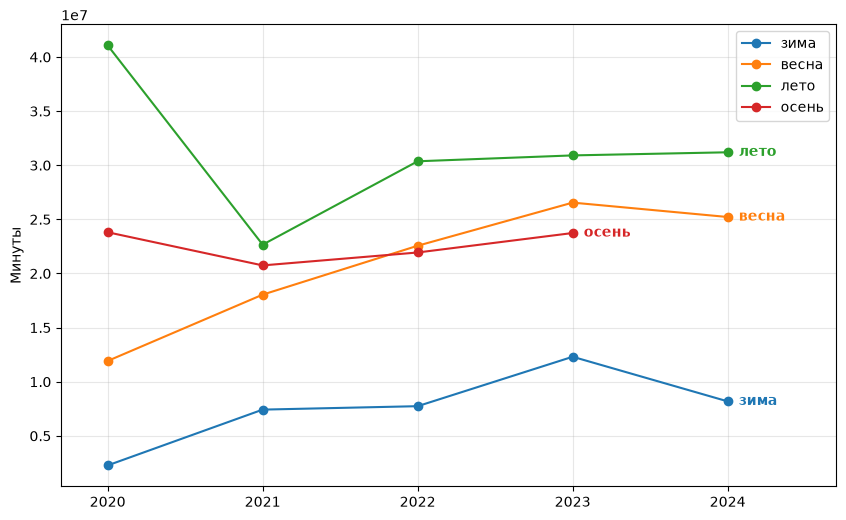

In [40]:
fig, ax = plt.subplots(figsize=(10, 6))

lines, labels = {}, {}
for season in pivot.columns:
    s = pivot[season].dropna()          # у осени 2024 нет данных
    line, = ax.plot(s.index, s.values, marker='o', label=season)
    lines[season] = line

    # подпись с названием сезона на конце линии
    labels[season] = ax.annotate(
        season,
        xy=(s.index[-1], s.values[-1]),
        xytext=(8, 0), textcoords='offset points',
        color=line.get_color(), fontweight='bold', va='center'
    )

ax.set_xticks(pivot.index)
ax.set_xlim(pivot.index.min() - 0.3, pivot.index.max() + 0.7)  # место под подписи
ax.set_ylabel('Минуты')
ax.grid(alpha=0.3)
leg = ax.legend()

legend_map = {}
for leg_line, season in zip(leg.get_lines(), pivot.columns):
    leg_line.set_picker(True)
    leg_line.set_pickradius(8)
    legend_map[leg_line] = season

plt.show()

### Вывод по гипотезе 1 - Насколько уменьшится аренда (длительность аренды) велосипедов от зимних условий, (это гололед, снег, температура), стоит ли заменить летние велосипеды на более снаряженные

- Можно отследить динамику что от года к году количество аренды в минутах зимой возрастает, если не брать 2024 год, так как он закончился
- К сожалению у меня нет данных об отзывах в зимних условиях на основе их можно было бы принять решение об дополнительном оборудоавнии для зимних условий
- Возможно 2024 год закроется с количеством более 1 миллинона минут аренды и побъет рекорд 2023 года